In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")


In [8]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# data cleaning

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")
df.dropna(inplace=True)

 check missing values

In [12]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn Distribution

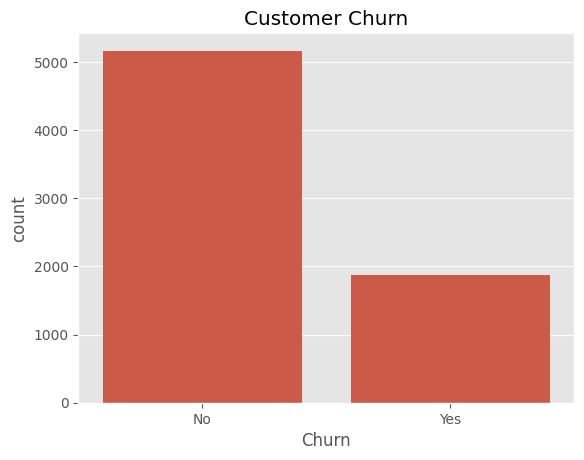

In [13]:
sns.countplot(x="Churn", data=df)
plt.title("Customer Churn")
plt.show()


Contract Type vs Churn

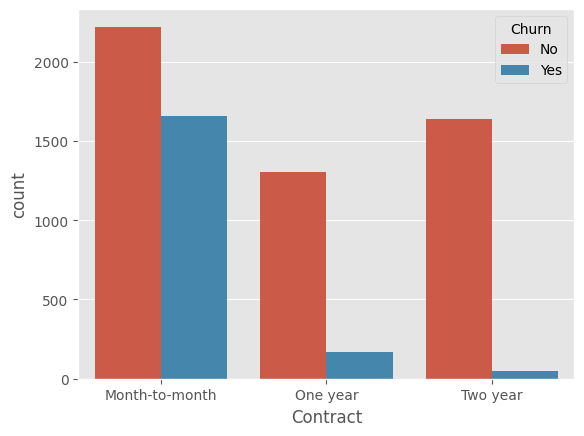

In [14]:
sns.countplot(x="Contract",hue="Churn",data=df)
plt.show()

Monthly Charges Distribution

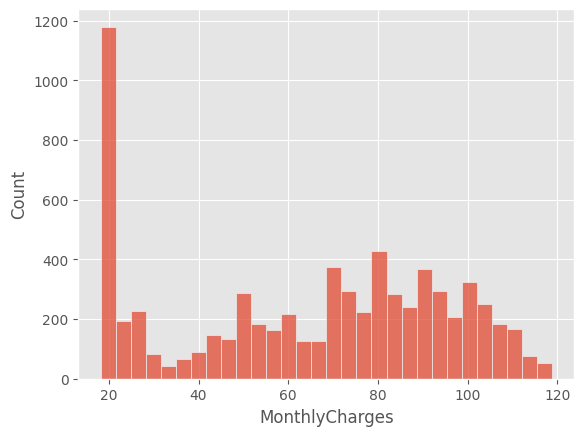

In [15]:
plt.Figure(figsize=(8,5))
sns.histplot(df["MonthlyCharges"], bins=30)
plt.show()

Boxplot

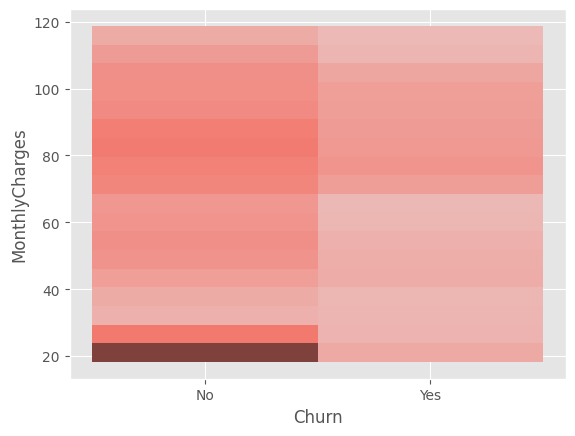

In [18]:
plt.Figure(figsize=(8,5))
sns.histplot(x="Churn",y="MonthlyCharges",data=df)
plt.show()

Correlation Heatmap

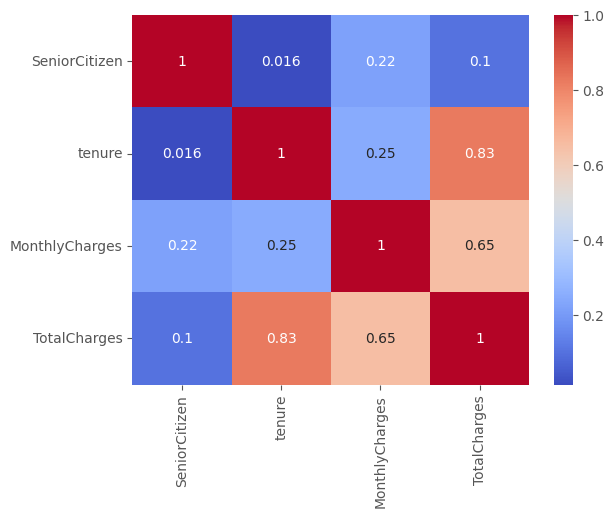

In [19]:
plt.Figure(figsize=(8,5))

numeric = df.select_dtypes(include=np.number)
sns.heatmap(numeric.corr(),annot=True,cmap="coolwarm")
plt.show()

Feature Engineering
1 Tenure Bands
2 Monthly Charge Category

In [31]:
df["TenureBand"]=pd.cut(df["tenure"],
                        bins=[0,3,12,24,48,72],
                        labels=["0-3","3-12","12-24","24-48","48-72"])
print(df["TenureBand"])
plt.show()

0         0-3
1       24-48
2         0-3
3       24-48
4         0-3
        ...  
7038    12-24
7039    48-72
7040     3-12
7041     3-12
7042    48-72
Name: TenureBand, Length: 7032, dtype: category
Categories (5, str): ['0-3' < '3-12' < '12-24' < '24-48' < '48-72']


In [32]:
df["TenureBand"]=pd.cut(df["tenure"],
                        bins=[0,3,12,24,48,72],
                        labels=["0-3","3-12","12-24","24-48","48-72"])
print(df["TenureBand"].head())
plt.show()

0      0-3
1    24-48
2      0-3
3    24-48
4      0-3
Name: TenureBand, dtype: category
Categories (5, str): ['0-3' < '3-12' < '12-24' < '24-48' < '48-72']


In [33]:
df["ChargeCategory"]=pd.cut(df["MonthlyCharges"],
                            bins=[0,35,70,120],
                            labels=["Low","Medium","High"])
print(df["ChargeCategory"])
plt.show()

0          Low
1       Medium
2       Medium
3       Medium
4         High
         ...  
7038      High
7039      High
7040       Low
7041      High
7042      High
Name: ChargeCategory, Length: 7032, dtype: category
Categories (3, str): ['Low' < 'Medium' < 'High']


In [34]:
df["ChargeCategory"]=pd.cut(df["MonthlyCharges"],
                            bins=[0,35,70,120],
                            labels=["Low","Medium","High"])
print(df["ChargeCategory"].head())
plt.show()

0       Low
1    Medium
2    Medium
3    Medium
4      High
Name: ChargeCategory, dtype: category
Categories (3, str): ['Low' < 'Medium' < 'High']


Contract Bucket

In [37]:
df["ContractBucket"]=df["Contract"].replace({
    "Month-to-month":"Monthly",
    "One year":"Yearly",
    "Two year":"Long-Term"
})
print(df["ContractBucket"])

0         Monthly
1          Yearly
2         Monthly
3          Yearly
4         Monthly
          ...    
7038       Yearly
7039       Yearly
7040      Monthly
7041      Monthly
7042    Long-Term
Name: ContractBucket, Length: 7032, dtype: str


Churn Rate

In [38]:
churn_rate=df.groupby("ContractBucket")["Churn"].value_counts(normalize=True)

print(churn_rate)

ContractBucket  Churn
Long-Term       No       0.971513
                Yes      0.028487
Monthly         No       0.572903
                Yes      0.427097
Yearly          No       0.887228
                Yes      0.112772
Name: proportion, dtype: float64


Top Churn Segments

In [39]:
segment=df.groupby(["ContractBucket","TenureBand","Churn"]).size()

print(segment)

ContractBucket  TenureBand  Churn
Long-Term       0-3         No          6
                3-12        No         52
                12-24       No         90
                24-48       No        268
                            Yes         6
                48-72       No       1221
                            Yes        42
Monthly         0-3         No        430
                            Yes       595
                3-12        No        540
                            Yes       429
                12-24       No        459
                            Yes       278
                24-48       No        538
                            Yes       264
                48-72       No        253
                            Yes        89
Yearly          0-3         No         18
                            Yes         2
                3-12        No         92
                            Yes        11
                12-24       No        181
                            Yes        16


Save Cleaned Dataset

In [49]:
import os

print(os.path.exists("Cleaned_Customer_Churn.csv"))


True


### **Conclusion – Customer Churn Analysis**







* Analyzed a telecom customer dataset containing **7,043 customers** to understand churn behavior.
* Customers with **month-to-month contracts** showed the highest churn rate compared to one-year and two-year contracts.
* Customers with **low tenure (0–3 months)** were more likely to leave the company.
* Higher **monthly charges** were associated with a greater likelihood of churn.
* Customers on **long-term contracts** had much lower churn, indicating stronger customer loyalty.
* Feature engineering (Tenure Band and Contract Bucket) helped identify high-risk customer segments more effectively.
* The analysis suggests that telecom companies should focus on **early customer engagement**, **personalized retention offers**, and **encouraging long-term contracts** to reduce churn and improve customer retention.

This project demonstrates how **Python, Pandas, NumPy, Matplotlib, and Seaborn** can be used to clean data, perform exploratory data analysis (EDA), create visualizations, and generate actionable business insights.